# Chapter 7: kMeans

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.datasets import make_blobs
from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from scipy.stats import mode

## 7.1 Introduction & Motivation

In contrary to regression and classification, clustering is a bit more abstract. Instead of knowing what value we want to predict and what kind of values we can expect from it, we are now leaving all of that behind us and putting our trust in our created model. This time, we are passing our data and asking ourself the following question: within the given data, are there any **groups** or **clusters** of datapoints that belong together?

This kind of information might not seem as valueble as regression or classification at first glance, but is extremely useful in cases such as customer segmentation (so you know what your audience groups are and who to target), fraud detection (by identifying outliers who don't really fit in a cluster) or data organisations (such as grouping articles).

## 7.2 Problem Setting

In today's notebook we will be looking at two different datasets. First we will explore cluistering as segmentation mechanic using the mall customers dataset, after which we will try to mold it into a predictive model by revisiting the wine dataset.

The mall customers dataset contains data regarding, you guessed it, mall customers. Each customer has a certain gender, age, annual income (in k$) and a spending score between 0 and 100. We are trying to visulalize which groups of people have a similar spending power, so we can target our advertisements accordingly.

## 7.3 Model

As always, let's have a look at the data first.

In [4]:
df = pd.read_csv('Mall_Customers.csv')
df.head(10)

,CustomerID,Gender,Age,Annual Income,Spending Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [5]:
dummygender = pd.get_dummies(df["Gender"], dtype=int)
df = df.drop("Gender", axis=1)
df = pd.concat([df, dummygender], axis=1)

In [3]:
df.dtypes

CustomerID         int64
Gender            object
Age                int64
Annual Income      int64
Spending Score     int64
dtype: object

In [15]:
df

,CustomerID,Age,Annual Income,Spending Score,Female,Male
0,1,19,15,39,0,1
1,2,21,15,81,0,1
2,3,20,16,6,1,0
3,4,23,16,77,1,0
4,5,31,17,40,1,0
...,...,...,...,...,...,...
195,196,35,120,79,1,0
196,197,45,126,28,1,0
197,198,32,126,74,0,1
198,199,32,137,18,0,1


#### Question 1: Try and plot a heatmap to further explore the data. If you run into any errors, fix it using a method we've seen before just like the previous exercise.

<Axes: >

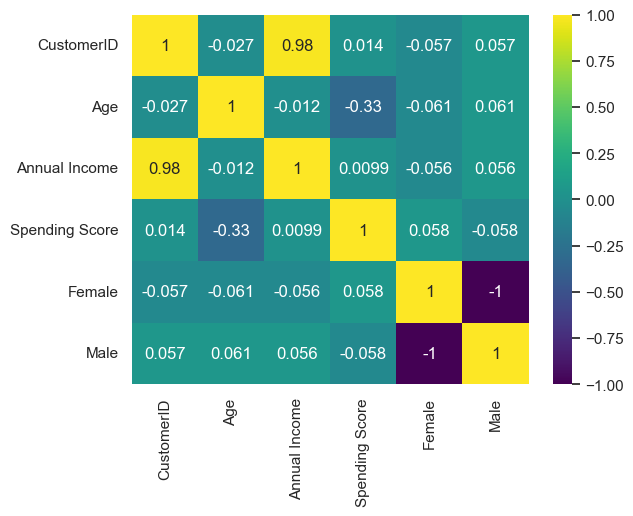

In [5]:
sns.heatmap(df.corr(), cmap="viridis", annot=True)

#### Question 2: Do you notice any strange or unexpected relation? Can you think of why this is? Is it pure chance or is there more going on?

In [ ]:
# There is an anomaly where CustomerID and Annual Income are very strongly correlated to each other.
# However this is likely the result of the dataset having sorted the annual income, then applying customer ID's in that same order.
# This creates a near perfect correlation between customerID and annual income. But since customerID doesn't mean anything aside from being a unique identifier, this correlation becomes useless.

# Aside from that, there is a moderate negative correlation between age and spending score. Plausable, as people's spending tends to change based on age.

## 7.4 Model Evaluation

#### Question 3: We will be trying to visualize our data. Since a simple to understand 2D plot can only support two variables (a dependant and an independant one) we are forced to limit our model to two variables. Our dependant variable will be Spending Score as that is what we are trying to visualize. Pick an independant variable and figure out the best value for k.

Chosen independant variable: Age

In [3]:
import warnings
warnings.filterwarnings("ignore")

### Visualizing both variables

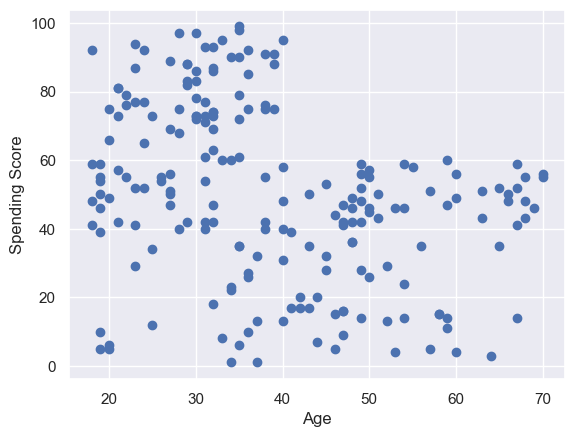

In [12]:
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.scatter(df["Age"], df["Spending Score"])

From this visualization, we can observe some clustering:
- spending score clearly decreases at age 40, where it then plateaus.
- High datapoint concentration can be observed at:
    - 20-40 years old
    - 45-55 years old
    - 65-70 years old

The spread of the datapoints can be attributed to:
- Personal factors (habits, preferance, ...)
- External factors (sales, new releases/launches, ...)
- etc.

### Creating the model

In [36]:
X = df[["Age"]]
y = df["Spending Score"]

kmeans = KMeans(n_clusters=5, random_state=0)
clusters = kmeans.fit_predict(X)

In [ ]:
clusters # Index = Index of the X dataset (age). Number = Cluster the datapoint of X dataset was assigned to.

array([4, 4, 4, 4, 1, 4, 3, 4, 0, 1, 0, 3, 0, 4, 3, 4, 3, 4, 2, 3, 3, 4,
       2, 1, 2, 1, 2, 3, 3, 4, 0, 4, 2, 4, 2, 4, 3, 1, 3, 4, 0, 4, 2, 1,
       2, 4, 2, 1, 1, 1, 2, 1, 1, 0, 2, 2, 2, 0, 1, 2, 0, 4, 0, 2, 0, 4,
       3, 0, 4, 1, 0, 2, 0, 0, 0, 1, 2, 3, 4, 2, 0, 3, 0, 2, 4, 2, 2, 4,
       3, 2, 0, 4, 2, 3, 1, 4, 2, 1, 2, 4, 4, 2, 0, 1, 2, 4, 0, 2, 0, 0,
       0, 4, 3, 4, 4, 4, 0, 2, 2, 2, 1, 3, 3, 3, 4, 1, 3, 3, 0, 3, 2, 3,
       4, 1, 4, 1, 2, 1, 4, 3, 0, 1, 1, 1, 4, 1, 2, 1, 3, 3, 3, 3, 2, 3,
       2, 1, 3, 1, 3, 1, 2, 1, 4, 1, 2, 3, 3, 1, 3, 1, 3, 1, 3, 3, 2, 1,
       0, 1, 0, 3, 3, 1, 2, 1, 3, 1, 2, 1, 3, 3, 3, 1, 1, 3, 2, 3, 2, 1,
       1, 1])

### Choosing the best k with the elbow method

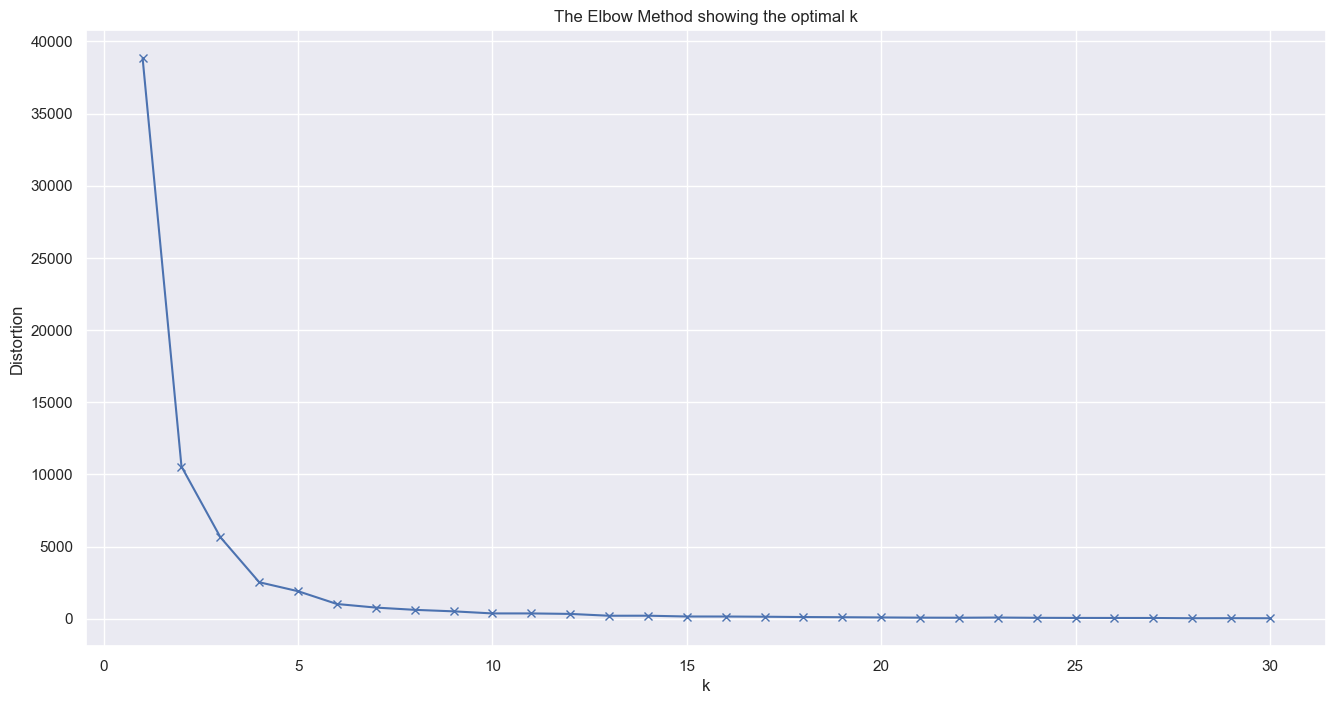

In [37]:
distortions = []
K = range(1,31)
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(X)
    distortions.append(kmeanModel.inertia_)

plt.figure(figsize=(16,8))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method showing the optimal k')
plt.show()

From this graph, we can conclude that 4 is the best value for k (as that is where the "elbow" forms). 

However, I like 5 more. So we'll take that instead.

#### Question 4: Plot a graph showing the Spending Score in function of the column you picked. Make sure you can visualize each individual cluster and its centroids.

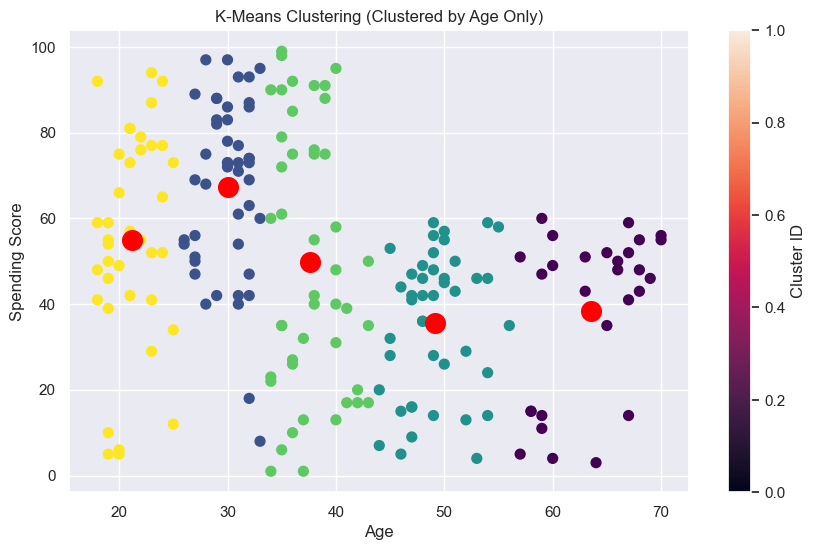

In [14]:
centroid_ages = kmeans.cluster_centers_
centroid_scores = df.groupby(clusters)["Spending Score"].mean() # => Since we are taking the average, the centroid positions are not 100% correct.

plt.figure(figsize=(10, 6))

plt.scatter(df["Age"], df["Spending Score"], c=clusters, cmap='viridis', s=50)
plt.scatter(centroid_ages, centroid_scores, c='red', marker='o', s=200, label='Centroids')

plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.title("K-Means Clustering (Clustered by Age Only)")

plt.colorbar(label='Cluster ID')

plt.show()

In [53]:
labels = np.zeros_like(clusters)
for i in range(5):
    ## only select the positions where the current number is i
    mask = (clusters == i) # Mask = extra filtering.
    ## figure out which number this most likely represents and map it
    ## mode picks the value that occurs the most
    labels[mask] = mode(y[mask])[0]

accuracy_score(y, labels)

0.075

(This doesn't work, because spending score and age are continious variables. This essentially garantuees a low accuracy: as we can really only come close the the actual spending score and rarely guess the exact number. Accuracy demands you guess the exact score, which is why it's so low))

#### Question 5: You've explored the relation of one column with Spending Score, now explore all other columns. Are there any more insights to be revealed?

In [22]:
AllLabels = ["Annual Income", "Age", "Female"]
mydict = {}

for label in AllLabels:
    X = df[[label]]
    y = df["Spending Score"]

    kmeans = KMeans(n_clusters=4, random_state=0)
    clusters = kmeans.fit_predict(X)

    labels = np.zeros_like(clusters)
    for i in range(6):
        ## only select the positions where the current number is i
        mask = (clusters == i) # Mask = extra filtering.
        ## figure out which number this most likely represents and map it
        ## mode picks the value that occurs the most
        labels[mask] = mode(y[mask])[0]

    cluster_means = df.groupby(clusters)["Spending Score"].mean()
    predictions = cluster_means[clusters].values

    # 2. Calculate the MSE
    # We compare the actual Spending Score to the average of their assigned cluster
    mse = mean_squared_error(df["Spending Score"], predictions)

    mydict[label] = mse

for key in mydict.keys():
    print(f"{key} - {mydict[key]}")

Annual Income - 663.4456527777779
Age - 540.2380576576576
Female - 661.2795413961039


#### Question 6: Based on this, does our preferred value in the correlation matrix for picking columns still hold up? What would you change?

From this we can observe that the least mistakes were made by using Age as the independant variable. It is therefore the best for creating realistic clusters in our dataset and is best for finding any meaningful correlation with spending score.

## 7.5 Questions

#### Question 1: See section 7.3
#### Question 2: See section 7.3
#### Question 3: See section 7.4
#### Question 4: See section 7.4
#### Question 5: See section 7.4
#### Question 6: See section 7.4
#### Question 7: Revisit the old wine dataset. Copy it to your current folder and import it. Drop the Id column just like we did in the notebook on decision trees.

In [7]:
Wine = pd.read_csv("Wine.csv")
Wine = Wine.drop("Id", axis=1)
Wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


<Axes: >

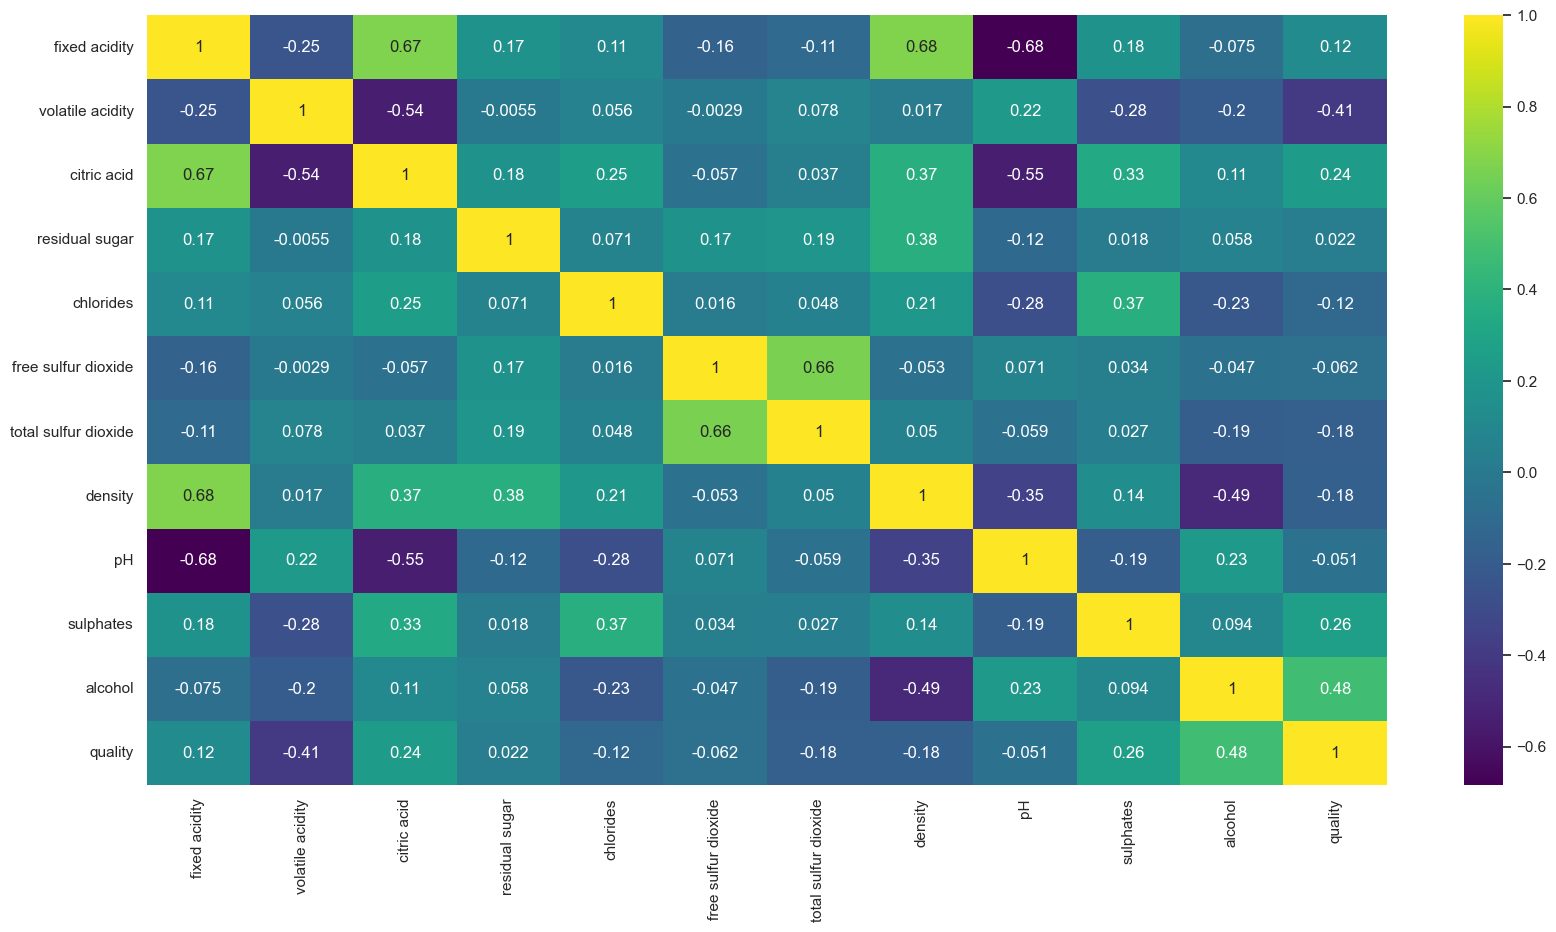

In [8]:
plt.figure(figsize=[20, 10])
sns.heatmap(Wine.corr(), annot=True, cmap="viridis")

#### Question 8: We want to explore the vizualization of quality as the dependant variable and all other variables. Calculate the best value of k for each graph (11 in total) and plot them. What can you learn from this?

In [9]:
np.sort(Wine["quality"].unique())

array([3, 4, 5, 6, 7, 8], dtype=int64)

### Using all variables
(This makes it unplotable, because we can't visualize 11 dimensions)

In [12]:
X = Wine[["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"]]
y = Wine["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

kmeans = KMeans(n_clusters=6, random_state=0)
clusters = kmeans.fit_predict(X)

### Using the best variable
(Alcohol is has the highest correlation to quality compared to the other variables. It would be interesting to cluster it only based on alcohol percentages. Accuracy score does increase slightly as well)

In [24]:
X = Wine[["alcohol"]]
y = Wine["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

kmeans = KMeans(n_clusters=6, random_state=0)
clusters = kmeans.fit_predict(X)

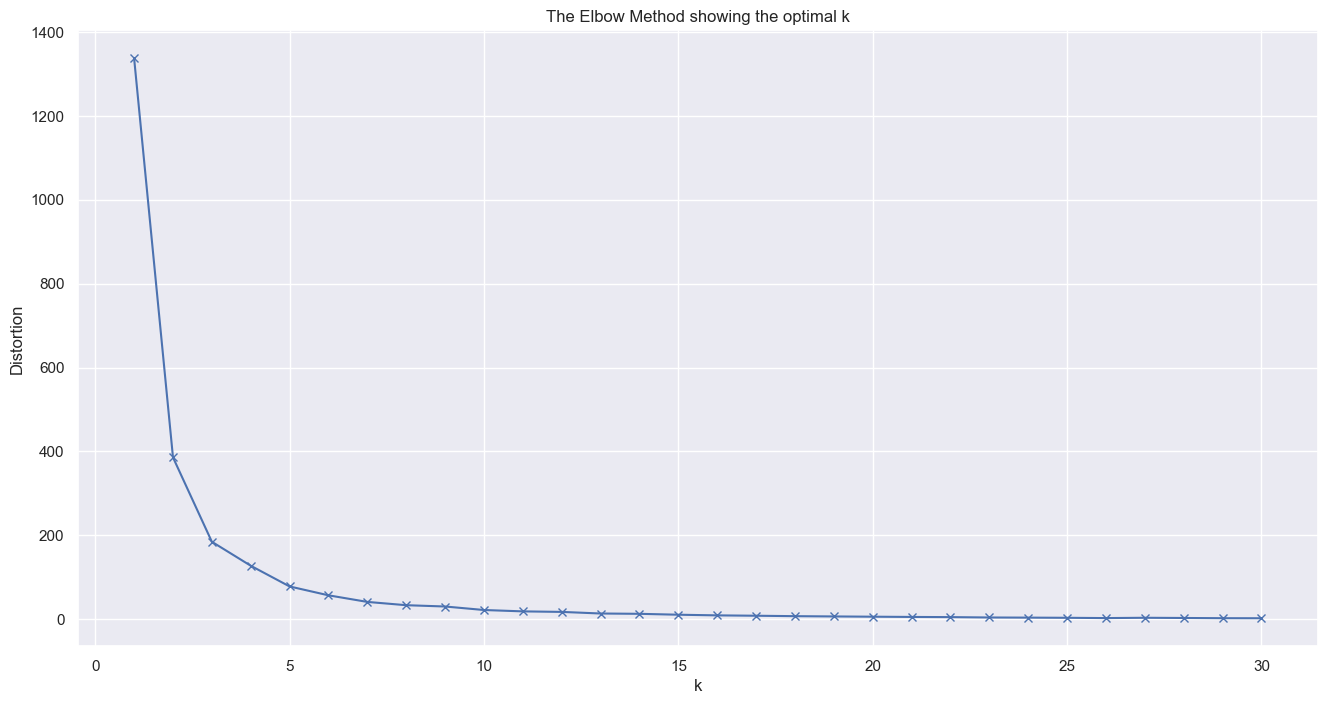

In [25]:
distortions = []
K = range(1,31)
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(X)
    distortions.append(kmeanModel.inertia_)

plt.figure(figsize=(16,8))
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method showing the optimal k')
plt.show()

From this visualization, we can observe that a good value for k would be 6.

This would also make sense for the wine dataset; as there are 6 total wine qualities. Having exactly 1 cluster for each quality level makes more sense and can open the door to predictive analysis.

#### Question 9: Try and use clustering as a way to predict your quality. Feel free to use all columns for this model. Think of how many clusters you would expect in this case!

What better way to try and predict our labels than with a confusion matrix?

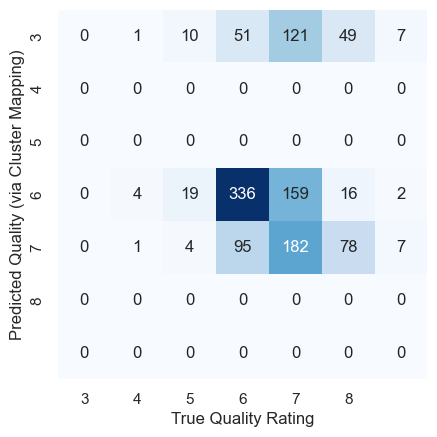

In [29]:
from sklearn.metrics import confusion_matrix

mat = confusion_matrix(y, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False, cmap="Blues",
            xticklabels=np.unique(y), 
            yticklabels=np.unique(y))
plt.xlabel('True Quality Rating')
plt.ylabel('Predicted Quality (via Cluster Mapping)')
plt.show()

#### Question 10: Evaluate the model. Is it any good for this kind of prediction? Why is this? Are there any noteable differences when seen against predicting the digits dataset? What makes a dataset 'good' to use with clustering for predicting a value? Elaborate based on your findings from question 8 and 9.

In [26]:
from sklearn.metrics import accuracy_score

labels = np.zeros_like(clusters)
for i in range(1,7):
    ## only select the positions where the current number is i
    mask = (clusters == i) # Mask = extra filtering.
    ## figure out which number this most likely represents and map it
    ## mode picks the value that occurs the most
    labels[mask] = mode(y[mask])[0]

accuracy_score(y, labels)

0.45359019264448336

### To answer question 10:

As was clear by the confusion matrix and the accuracy score: this model is not good for predicting quality of wine.

But that's ok. KMeans clustering was never meant to predict anything at all anyways. It's designed in cases where you don't know / don't have any labels for your datapoints at all. The wine dataset is therefore a bad example: since we do actually know the quality labels. Applying Kmeans to it is worse than Knn clustering; because one is unsupervised and the other is supervised.

However, there is a noticable change in accuracy of the Kmeans model in this assignment. Earlier on the customers dataset, I applied the same technique to discover an accuracy score. This score was near 0, since the customer dataset used continuous variables. As we discussed in that section: the chance of your model then exactly guessing that number are extremely low.

Remarkably, the accuracy score has drastically increased in this model. That is because this dataset (the wine dataset) actually has predefined labels! The chance of our model then guessing that label is much more likely. The same goes for the numbers dataset.
To explain then why the accuracy score of the wine model is much lower compared to that of the digits model: it's because the clusters in the digits model are way more destint from each other. It's pretty hard to mix "0" and "1" from each other, but for the wine model: the difference between quality 5 and 6 based on alcohol can easily become much harder to guess. In short: the wine model has less distinct clusters than the digits model, which results in a lower accuracy score for the wine model.

In order for a clustering to predict a value, the values need to be labled already. The irony is that if you then use Kmeans on datapoints with known labels: you are essentially hindering yourself because you're treating it as if you don't know the labels, but you actually do. That's why litteraly any other logistical regression model is better for datasets with known labels.